In [ ]:
%%bash
pip install -q rasterio scikit-learn matplotlib pillow opencv-python
pip install -q git+https://github.com/openai/CLIP.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.1 MB/s eta 0:00:00


In [ ]:
%%bash
wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O /content/sam_vit_b.pth
pip install -q git+https://github.com/facebookresearch/segment-anything.git

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import rasterio
from PIL import Image
from rasterio.windows import Window
from rasterio.warp import reproject, Resampling

import clip
from segment_anything import sam_model_registry, SamPredictor

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["axes.titlesize"] = 12


In [ ]:
before_path = "/content/drive/MyDrive/data/sentinel_before.tif"
after_path  = "/content/drive/MyDrive/data/sentinel_after.tif"
gt_path     = "/content/drive/MyDrive/data/gfc_loss_mask.tif"

sam_checkpoint = "/content/sam_vit_b.pth"
crop = Window(1000, 1000, 1500, 1500)
sam_model_type = "vit_b"


In [ ]:
def compute_ndvi(red, nir):
    red = red.astype(np.float32)
    nir = nir.astype(np.float32)
    denom = nir + red
    ndvi = np.divide(
        nir - red,
        denom,
        out=np.zeros_like(denom, dtype=np.float32),
        where=np.abs(denom) > 1e-6
    )
    ndvi = np.clip(ndvi, -1.0, 1.0)
    ndvi = np.nan_to_num(ndvi, nan=0.0, posinf=0.0, neginf=0.0)
    return ndvi

def robust_scale_to_uint8(x, p_low=2, p_high=98):
    lo, hi = np.percentile(x, (p_low, p_high))
    x = (x - lo) / (hi - lo + 1e-6)
    x = np.clip(x, 0, 1)
    return (x * 255).astype(np.uint8)

def make_rgb(red, green, blue):
    return np.stack([
        robust_scale_to_uint8(red),
        robust_scale_to_uint8(green),
        robust_scale_to_uint8(blue)
    ], axis=-1)

def normalize_map(x):
    lo, hi = np.percentile(x, (5, 95))
    x = (x - lo) / (hi - lo + 1e-6)
    return np.clip(x, 0, 1)

def overlay_mask_on_rgb(rgb, mask, alpha=0.45):
    out = rgb.copy()
    red = np.zeros_like(out)
    red[..., 0] = 255
    mask_bool = mask.astype(bool)
    out[mask_bool] = ((1 - alpha) * out[mask_bool] + alpha * red[mask_bool]).astype(np.uint8)
    return out

def compute_metrics(pred, gt):
    pred = pred.astype(np.uint8)
    gt = gt.astype(np.uint8)

    tp = np.sum((pred == 1) & (gt == 1))
    tn = np.sum((pred == 0) & (gt == 0))
    fp = np.sum((pred == 1) & (gt == 0))
    fn = np.sum((pred == 0) & (gt == 1))

    acc = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    intersection = np.sum((pred == 1) & (gt == 1))
    union = np.sum((pred == 1) | (gt == 1))
    iou = intersection / (union + 1e-8)

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
    }

def print_metrics(title, metrics):
    print(title)
    print("-" * len(title))
    print("Accuracy :", round(metrics["accuracy"], 4))
    print("Precision:", round(metrics["precision"], 4))
    print("Recall   :", round(metrics["recall"], 4))
    print("F1-score :", round(metrics["f1"], 4))
    print("IoU      :", round(metrics["iou"], 4))
    print("TP       :", metrics["tp"])
    print("TN       :", metrics["tn"])
    print("FP       :", metrics["fp"])
    print("FN       :", metrics["fn"])
    print()

def plot_hist(data, title, bins=50):
    plt.figure(figsize=(6, 4))
    plt.hist(data.ravel(), bins=bins)
    plt.title(title)
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


In [ ]:
src_before = rasterio.open(before_path)
src_after  = rasterio.open(after_path)
src_gt     = rasterio.open(gt_path)

before_crop = src_before.read(window=crop).astype(np.float32)
after_crop  = src_after.read(window=crop).astype(np.float32)

target_transform = src_before.window_transform(crop)
target_crs = src_before.crs
target_height = before_crop.shape[1]
target_width = before_crop.shape[2]

gt_aligned = np.zeros((target_height, target_width), dtype=np.uint8)

reproject(
    source=rasterio.band(src_gt, 1),
    destination=gt_aligned,
    src_transform=src_gt.transform,
    src_crs=src_gt.crs,
    dst_transform=target_transform,
    dst_crs=target_crs,
    resampling=Resampling.nearest
)

gt_bin = (gt_aligned > 0).astype(np.uint8)

print("Before crop shape:", before_crop.shape)
print("After crop shape :", after_crop.shape)
print("GT aligned shape :", gt_bin.shape)



Before crop shape: (24, 1500, 1500)
After crop shape : (24, 1500, 1500)
GT aligned shape : (1500, 1500)


In [ ]:
# Sentinel-2 band mapping
# B2 -> index 1 (Blue)
# B3 -> index 2 (Green)
# B4 -> index 3 (Red)
# B8 -> index 7 (NIR)

rgb_before = make_rgb(before_crop[3], before_crop[2], before_crop[1])
rgb_after  = make_rgb(after_crop[3],  after_crop[2],  after_crop[1])

# Extract bands
red_b, nir_b = before_crop[3], before_crop[7]
red_a, nir_a = after_crop[3],  after_crop[7]

red_b = red_b.astype(np.float32)
nir_b = nir_b.astype(np.float32)
red_a = red_a.astype(np.float32)
nir_a = nir_a.astype(np.float32)

#  NDVI computation
ndvi_before = compute_ndvi(red_b, nir_b)
ndvi_after  = compute_ndvi(red_a, nir_a)

#  Change in NDVI
dndvi = ndvi_after - ndvi_before

#  Clip to valid range
ndvi_before = np.clip(ndvi_before, -1, 1)
ndvi_after  = np.clip(ndvi_after, -1, 1)
dndvi       = np.clip(dndvi, -1, 1)

H, W = dndvi.shape

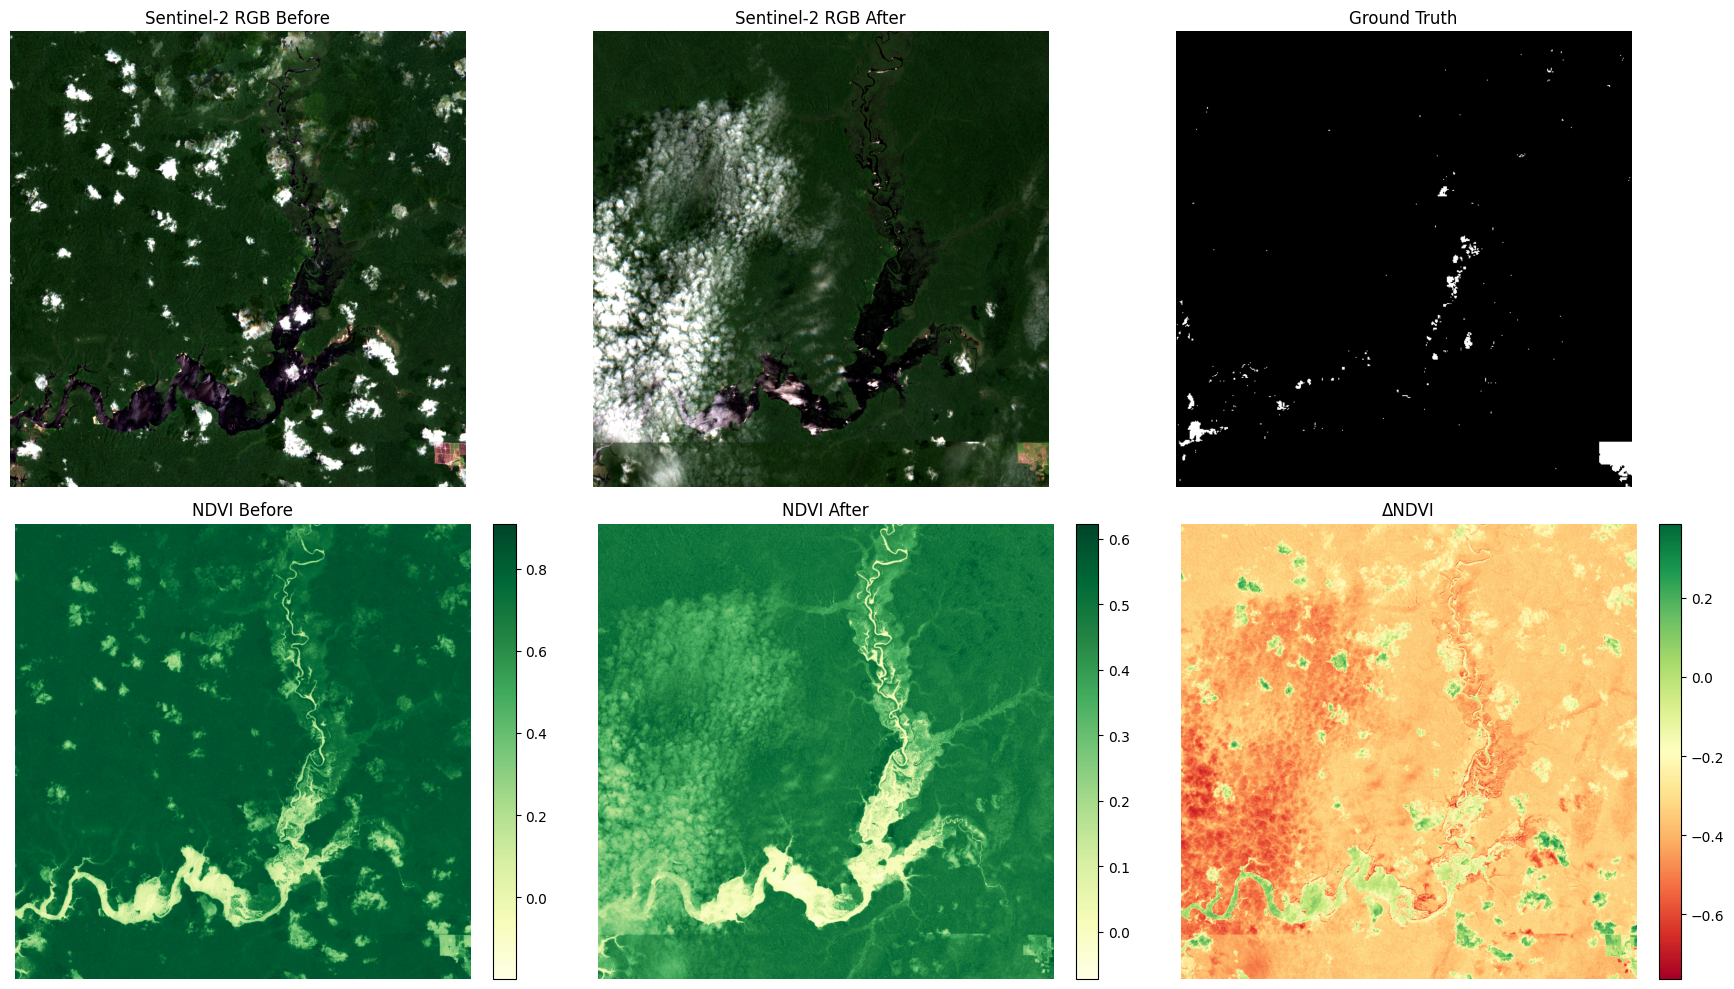

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(rgb_before)
axes[0, 0].set_title("Sentinel-2 RGB Before")
axes[0, 0].axis("off")

axes[0, 1].imshow(rgb_after)
axes[0, 1].set_title("Sentinel-2 RGB After")
axes[0, 1].axis("off")

axes[0, 2].imshow(gt_bin, cmap="gray")
axes[0, 2].set_title("Ground Truth")
axes[0, 2].axis("off")

im = axes[1, 0].imshow(ndvi_before, cmap="YlGn")
axes[1, 0].set_title("NDVI Before")
axes[1, 0].axis("off")
plt.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

im = axes[1, 1].imshow(ndvi_after, cmap="YlGn")
axes[1, 1].set_title("NDVI After")
axes[1, 1].axis("off")
plt.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04)

im = axes[1, 2].imshow(dndvi, cmap="RdYlGn")
axes[1, 2].set_title("ΔNDVI")
axes[1, 2].axis("off")
plt.colorbar(im, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


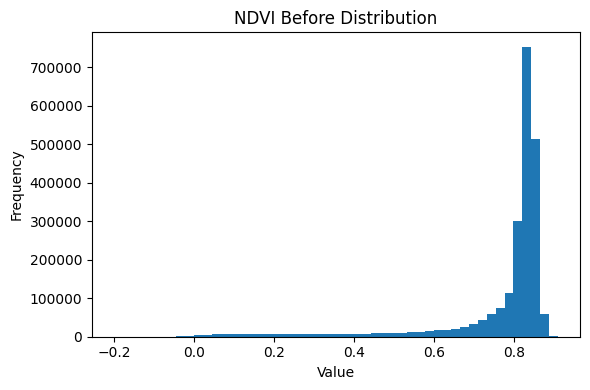

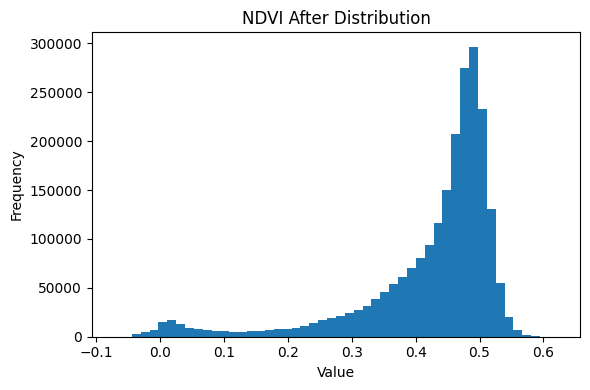

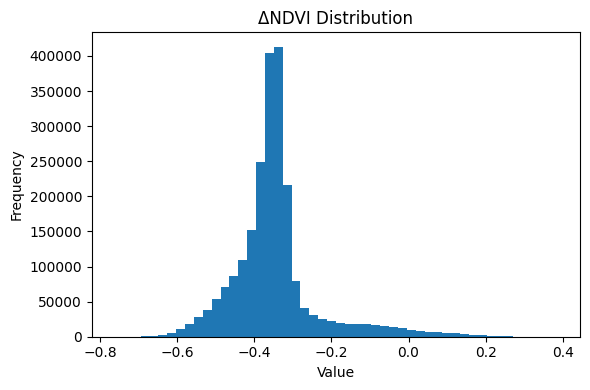

In [ ]:

plot_hist(ndvi_before, "NDVI Before Distribution")
plot_hist(ndvi_after, "NDVI After Distribution")
plot_hist(dndvi, "ΔNDVI Distribution")


In [ ]:
#CLIP setup
device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
clip_model.eval()
print("Using device:", device)

100%|███████████████████████████████████████| 338M/338M [00:05<00:00, 67.8MiB/s]


Using device: cpu


In [ ]:
forest_prompts = [
    "dense tropical forest from satellite top view",
    "lush green forest canopy satellite image",
    "undisturbed forest area satellite image"
]

deforestation_prompts = [
    "clear cut forest brown land satellite image",
    "deforestation patch exposed soil satellite",
    "logging activity area satellite view",
    "bare land where forest was removed satellite image"
]

prompts = forest_prompts + deforestation_prompts

forest_idx = list(range(len(forest_prompts)))
defor_idx = list(range(len(forest_prompts), len(prompts)))

# Tokenize
text_tokens = clip.tokenize(prompts).to(device)

with torch.no_grad():
    text_features = clip_model.encode_text(text_tokens)

    # Normalize 
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

In [ ]:
def get_clip_embedding(rgb_patch):
    img = Image.fromarray(rgb_patch.astype(np.uint8))
    x = clip_preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        feat = clip_model.encode_image(x)
        feat = feat / feat.norm(dim=-1, keepdim=True)
    return feat.squeeze(0).cpu().numpy()

def get_prompt_scores(rgb_patch):
    img = Image.fromarray(rgb_patch.astype(np.uint8))
    x = clip_preprocess(img).unsqueeze(0).to(device)

    with torch.no_grad():
        # Encode image
        img_feat = clip_model.encode_image(x)
        img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)

        # Compute similarity logits
        logits = (img_feat @ text_features.T)

        #  Temperature scaling (keep this)
        logits = logits * 100.0

        # Convert to probabilities
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    # Split scores
    forest_scores = probs[:len(forest_prompts)]
    defor_scores = probs[len(forest_prompts):]

    #  USE MAX instead of mean (VERY IMPORTANT)
    forest_score = forest_scores.max()
    defor_score = defor_scores.max()

    #  Contrastive score
    score = defor_score - forest_score

    return score, defor_score, forest_score

In [ ]:
patch = 128
patch_example = rgb_before[0:patch, 0:patch]
score, d, f = get_prompt_scores(patch_example)
print(f"Overall Score: {score:.4f}, Deforestation Score: {d:.4f}, Forest Score: {f:.4f}")

Overall Score: -0.0801, Deforestation Score: 0.2170, Forest Score: 0.2970


In [ ]:
patch = 128
stride = 64

print("Image size:", H, W)
print("Patch size:", patch)
print("Stride:", stride)


Image size: 1500 1500
Patch size: 128
Stride: 64


In [ ]:
raw_features = []
locs = []

for r in range(0, H - patch + 1, stride):
    for c in range(0, W - patch + 1, stride):
        pb = rgb_before[r:r+patch, c:c+patch]
        pa = rgb_after[r:r+patch, c:c+patch]
        dpatch = dndvi[r:r+patch, c:c+patch]
        ndvi_b_patch = ndvi_before[r:r+patch, c:c+patch]

        if pb.shape[:2] != (patch, patch) or pa.shape[:2] != (patch, patch):
            continue

        # PURE NDVI FEATURES 
        mean_drop = -np.mean(dpatch)
        frac_drop = np.mean(dpatch < -0.10)
        q10_drop = -np.percentile(dpatch, 10)
        q25_drop = -np.percentile(dpatch, 25)

        forest_start_strength = np.mean(ndvi_b_patch > 0.45)
        strong_drop_strength = np.mean(dpatch < -0.05)

        raw_features.append([
            mean_drop,
            frac_drop,
            q10_drop,
            q25_drop,
            forest_start_strength,
            strong_drop_strength
        ])

        locs.append((r, c))

raw_features = np.array(raw_features, dtype=np.float32)
print("Raw feature shape:", raw_features.shape)

Raw feature shape: (484, 6)


Text(0.5, 1.0, 'NDVI Mean Drop Distribution')

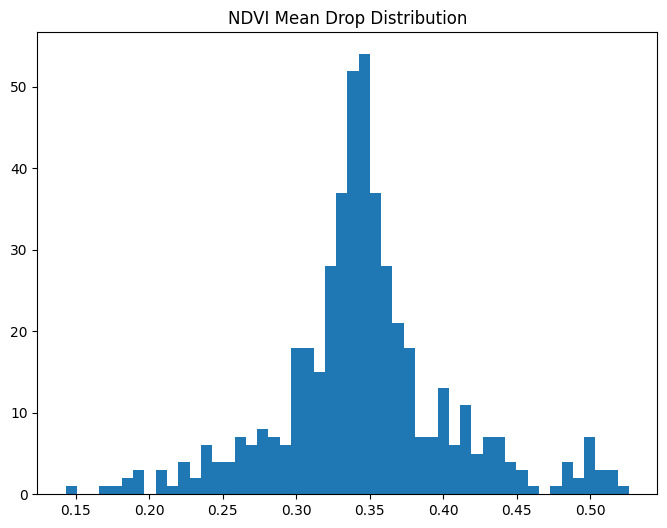

In [ ]:
plt.hist(raw_features[:, 0], bins=50)
plt.title("NDVI Mean Drop Distribution")

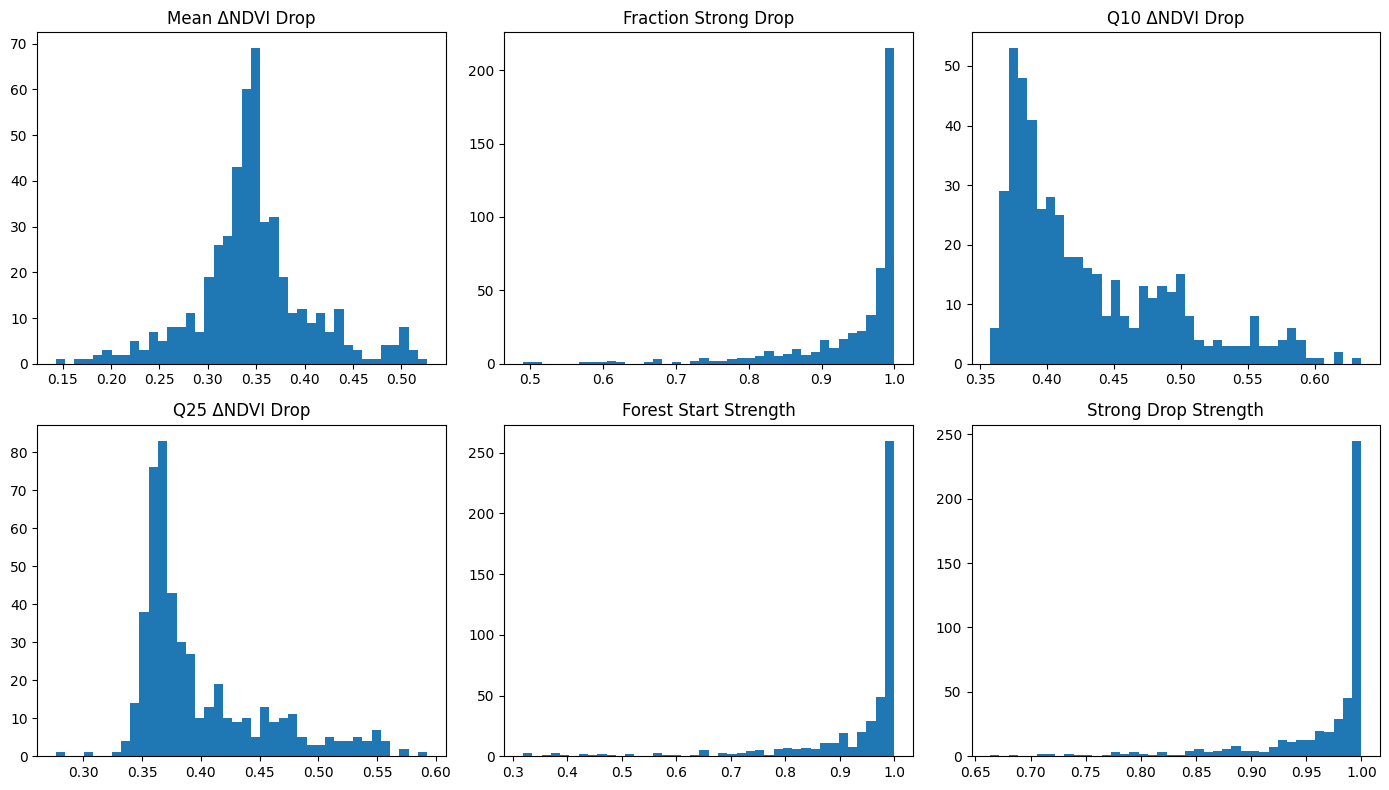

In [ ]:
feature_names = [
    "Mean ΔNDVI Drop",
    "Fraction Strong Drop",
    "Q10 ΔNDVI Drop",
    "Q25 ΔNDVI Drop",
    "Forest Start Strength",
    "Strong Drop Strength"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for i in range(len(feature_names)):
    axes[i].hist(raw_features[:, i], bins=40)
    axes[i].set_title(feature_names[i])

plt.tight_layout()
plt.show()

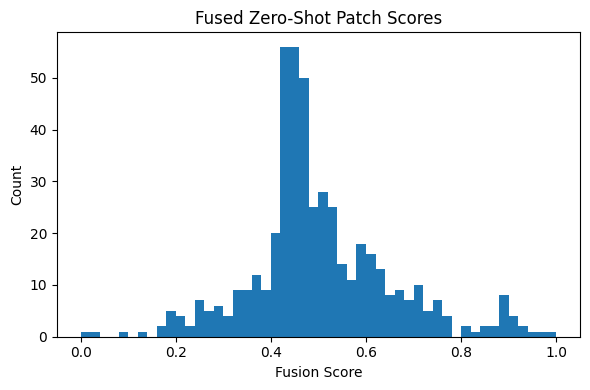

In [ ]:
mu = raw_features.mean(axis=0)
sigma = raw_features.std(axis=0) + 1e-8
norm_features = (raw_features - mu) / sigma

# Align feature direction
norm_features[:, 4] = -norm_features[:, 4]  # forest_start_strength

# Correct weights (6 features)
weights = np.array([0.25, 0.15, 0.20, 0.15, 0.15, 0.10], dtype=np.float32)

# Calculate all_patch_scores as the weighted sum of normalized features
all_patch_scores = np.sum(norm_features * weights, axis=1)

# Normalize scores to be between 0 and 1
all_patch_scores = (all_patch_scores - all_patch_scores.min()) / (
    all_patch_scores.max() - all_patch_scores.min() + 1e-8
)

plt.figure(figsize=(6, 4))
plt.hist(all_patch_scores, bins=50)
plt.title("Fused Zero-Shot Patch Scores")
plt.xlabel("Fusion Score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

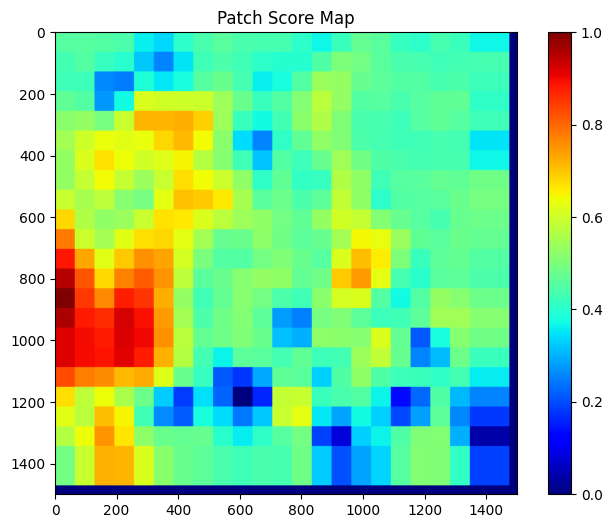

In [ ]:
score_map = np.zeros((H, W))

for (r, c), s in zip(locs, all_patch_scores):
    score_map[r:r+patch, c:c+patch] = s

plt.imshow(score_map, cmap='jet')
plt.title("Patch Score Map")
plt.colorbar()
plt.show()

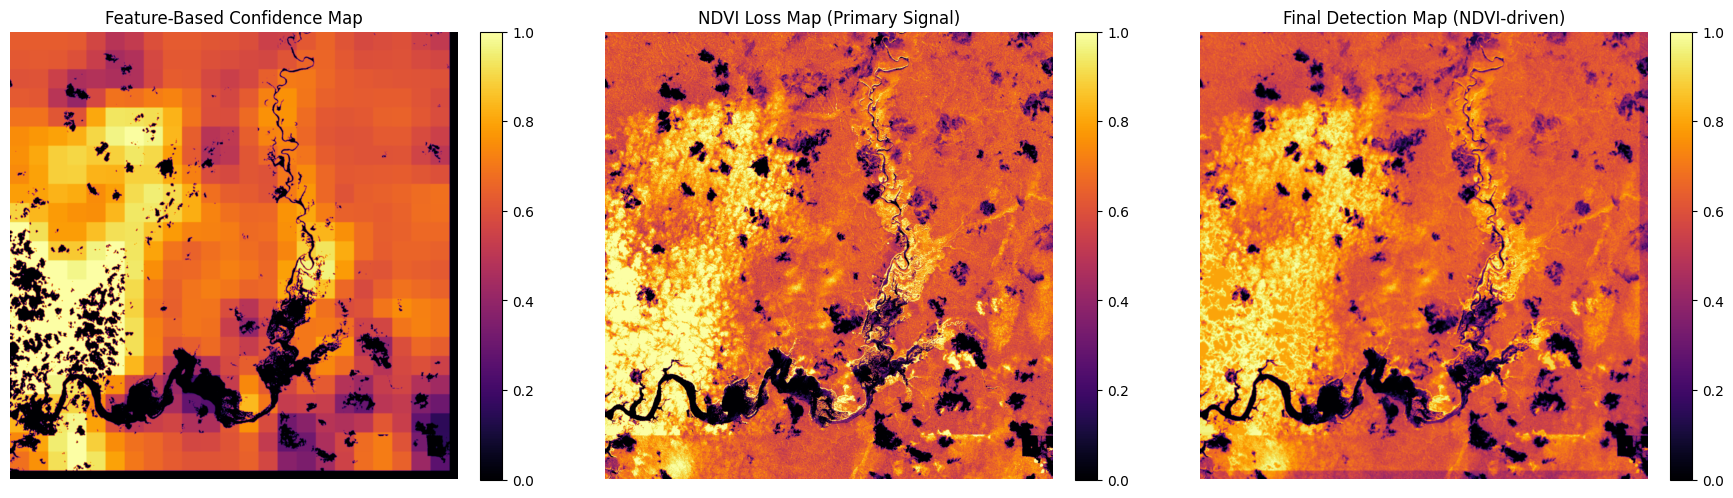

In [ ]:
score_map = np.zeros((H, W), dtype=np.float32)
count_map = np.zeros((H, W), dtype=np.float32)

for (r, c), s in zip(locs, all_patch_scores):
    score_map[r:r+patch, c:c+patch] += s
    count_map[r:r+patch, c:c+patch] += 1

score_map = score_map / np.maximum(count_map, 1)


valid_veg = (ndvi_before > 0.5)

water_mask = (
    (ndvi_before < 0.15) &
    (ndvi_after < 0.15)
)

cloud_mask = (
    (rgb_after[..., 0] > 200) &
    (rgb_after[..., 1] > 200) &
    (rgb_after[..., 2] > 200) &
    (ndvi_after < 0.35)
)

score_map = score_map * (1 - 0.5 * cloud_mask)

# Apply masks
score_map = score_map * valid_veg
score_map = score_map * (~water_mask)
score_map = score_map * (~cloud_mask)
score_map = score_map * (~stable_mask)


# NORMALIZATION
prob_map = normalize_map(score_map)


prob_map = cv2.GaussianBlur(prob_map, (5, 5), 0)

#  NDVI DOMINANT FUSION
dndvi_norm = normalize_map(-dndvi)

combined_map = 0.8 * dndvi_norm + 0.2 * prob_map

combined_map = cv2.GaussianBlur(combined_map, (5, 5), 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im = axes[0].imshow(prob_map, cmap="inferno")
axes[0].set_title("Feature-Based Confidence Map")
axes[0].axis("off")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

im = axes[1].imshow(dndvi_norm, cmap="inferno")
axes[1].set_title("NDVI Loss Map (Primary Signal)")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

im = axes[2].imshow(combined_map, cmap="inferno")
axes[2].set_title("Final Detection Map (NDVI-driven)")
axes[2].axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [ ]:

dndvi_norm = normalize_map(-dndvi)

#  feature support (weak influence)
prob_map = normalize_map(score_map)

#  NDVI dominant fusion (IMPORTANT)
combined_map = 0.8 * dndvi_norm + 0.2 * prob_map

combined_map = combined_map * valid_veg


# THRESHOLD
manual_th = 0.45
raw_pred = (combined_map > manual_th).astype(np.uint8)



roi_mask = (
    (ndvi_before > 0.35) &    
    (dndvi < -0.03)           
)

# Light guidance from detection map
roi_mask = roi_mask & (combined_map > 0.22)

roi_mask = roi_mask.astype(np.uint8)



#  MORPHOLOGY
kernel_open = np.ones((3, 3), np.uint8)
kernel_close = np.ones((5, 5), np.uint8)

roi_mask = cv2.morphologyEx(roi_mask, cv2.MORPH_OPEN, kernel_open)
roi_mask = cv2.morphologyEx(roi_mask, cv2.MORPH_CLOSE, kernel_close)



# CONNECTED COMPONENT FILTERING
num_labels, labels_cc, stats, _ = cv2.connectedComponentsWithStats(roi_mask, connectivity=8)

clean_roi = np.zeros_like(roi_mask)

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    # Balanced filtering (IMPORTANT)
    if area < 300 or area > 50000:
        continue

    clean_roi[labels_cc == i] = 1

roi_mask = clean_roi

In [ ]:
sam = sam_model_registry[sam_model_type](checkpoint=sam_checkpoint)
sam.to(device=device)
predictor = SamPredictor(sam)
predictor.set_image(rgb_after)

print("SAM loaded.")

SAM loaded.


In [ ]:
num_labels, labels_cc, stats, centroids = cv2.connectedComponentsWithStats(roi_mask, connectivity=8)

final_sam_mask = np.zeros((H, W), dtype=np.uint8)
component_visual = rgb_after.copy()

for cc_id in range(1, num_labels):
    x, y, w, h, area = stats[cc_id]

    if area < 150:  # relaxed
        continue

    component = (labels_cc == cc_id)
    ys, xs = np.where(component)

    if len(xs) < 3:
        continue

    comp_dndvi = dndvi[ys, xs]
    order = np.argsort(comp_dndvi)

    pos_points = []
    max_pos = min(8, len(order)) 
    for k in order[:max_pos]:
        pos_points.append([xs[k], ys[k]])

    point_coords = np.array(pos_points, dtype=np.float32)
    point_labels = np.array([1]*len(pos_points), dtype=np.int32)
    input_box = np.array([x, y, x+w, y+h])

    masks, scores, logits = predictor.predict(
        point_coords=point_coords,
        point_labels=point_labels,
        box=input_box,
        multimask_output=True
    )

    best_mask = masks[np.argmax(scores)].astype(bool)

    ndvi_support = (dndvi < 0.02)
    forest_support = (ndvi_before > 0.35)

    best_mask = best_mask & component & ndvi_support & forest_support

    if np.sum(best_mask) == 0:
        continue

    final_sam_mask[best_mask] = 1

    for px, py in pos_points:
        cv2.circle(component_visual, (int(px), int(py)), 3, (0,255,0), -1)

    cv2.rectangle(component_visual, (x, y), (x+w, y+h), (255,255,0), 1)

# DILATE 
kernel = np.ones((5,5), np.uint8)
final_sam_mask = cv2.dilate(final_sam_mask, kernel, iterations=1)

In [ ]:
kernel = np.ones((13, 13), np.uint8)
final_sam_mask = cv2.dilate(final_sam_mask, kernel, iterations=1)

In [ ]:
kernel_erode = np.ones((3, 3), np.uint8)
final_sam_mask = cv2.erode(final_sam_mask, kernel_erode, iterations=1)

In [ ]:
def compute_metrics(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    tp = np.logical_and(pred, gt).sum()
    tn = np.logical_and(~pred, ~gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()

    total = tp + tn + fp + fn + 1e-8

    accuracy = (tp + tn) / total
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn)
    }

In [ ]:
final_metrics = compute_metrics(final_sam_mask, gt_bin)
print_metrics("Final SAM Mask", final_metrics)

Final SAM Mask
--------------
Accuracy : 0.989
Precision: 0.4696
Recall   : 0.0702
F1-score : 0.1222
IoU      : 0.0651
TP       : 1729
TN       : 2223429
FP       : 1953
FN       : 22889



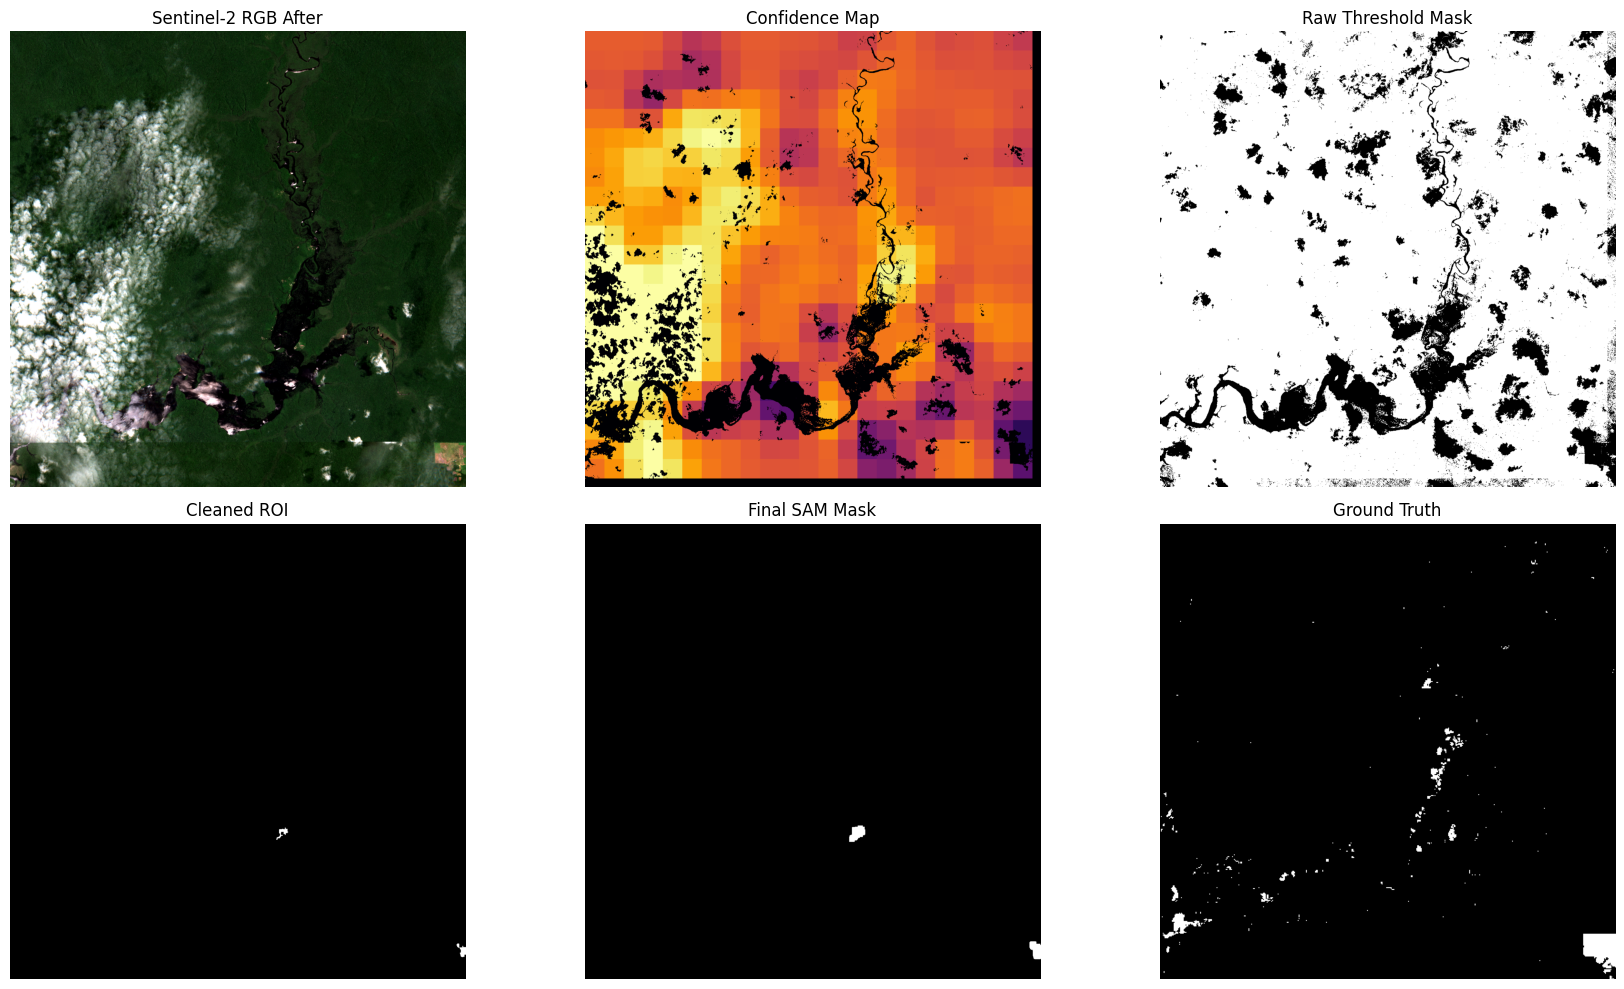

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(rgb_after)
axes[0, 0].set_title("Sentinel-2 RGB After")
axes[0, 0].axis("off")

axes[0, 1].imshow(prob_map, cmap="inferno")
axes[0, 1].set_title("Confidence Map")
axes[0, 1].axis("off")

axes[0, 2].imshow(raw_pred, cmap="gray")
axes[0, 2].set_title("Raw Threshold Mask")
axes[0, 2].axis("off")

axes[1, 0].imshow(roi_mask, cmap="gray")
axes[1, 0].set_title("Cleaned ROI")
axes[1, 0].axis("off")

axes[1, 1].imshow(final_sam_mask, cmap="gray")
axes[1, 1].set_title("Final SAM Mask")
axes[1, 1].axis("off")

axes[1, 2].imshow(gt_bin, cmap="gray")
axes[1, 2].set_title("Ground Truth")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()


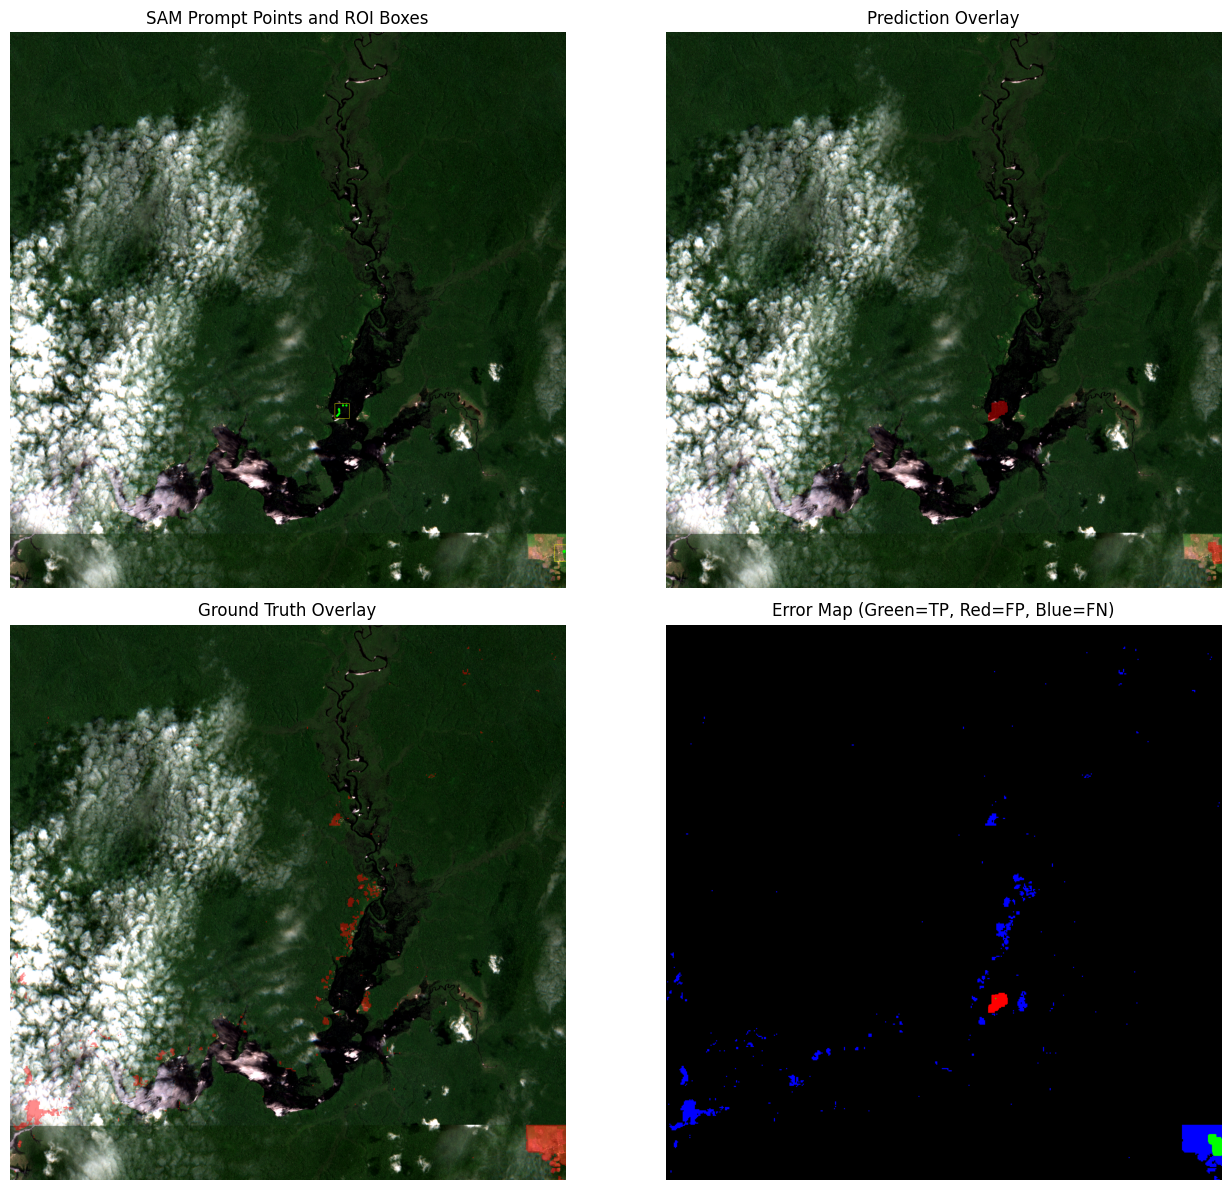

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(component_visual)
axes[0, 0].set_title("SAM Prompt Points and ROI Boxes")
axes[0, 0].axis("off")

axes[0, 1].imshow(overlay_mask_on_rgb(rgb_after, final_sam_mask))
axes[0, 1].set_title("Prediction Overlay")
axes[0, 1].axis("off")

axes[1, 0].imshow(overlay_mask_on_rgb(rgb_after, gt_bin))
axes[1, 0].set_title("Ground Truth Overlay")
axes[1, 0].axis("off")

error_map = np.zeros((H, W, 3), dtype=np.uint8)
tp = (final_sam_mask == 1) & (gt_bin == 1)
fp = (final_sam_mask == 1) & (gt_bin == 0)
fn = (final_sam_mask == 0) & (gt_bin == 1)

error_map[tp] = [0, 255, 0]   # green
error_map[fp] = [255, 0, 0]   # red
error_map[fn] = [0, 0, 255]   # blue

axes[1, 1].imshow(error_map)
axes[1, 1].set_title("Error Map (Green=TP, Red=FP, Blue=FN)")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()


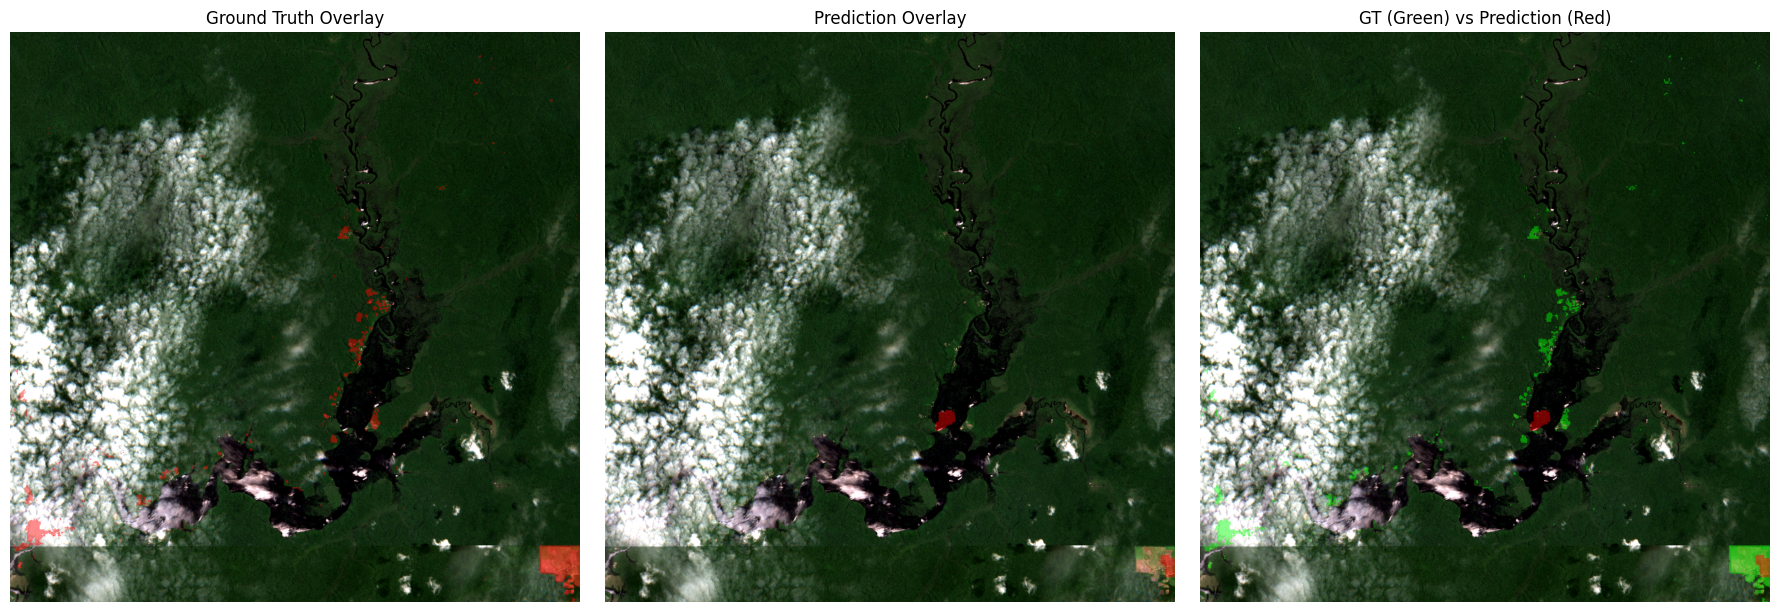

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(overlay_mask_on_rgb(rgb_after, gt_bin))
axes[0].set_title("Ground Truth Overlay")
axes[0].axis("off")

axes[1].imshow(overlay_mask_on_rgb(rgb_after, final_sam_mask))
axes[1].set_title("Prediction Overlay")
axes[1].axis("off")

comparison = rgb_after.copy()
green = np.zeros_like(comparison)
green[..., 1] = 255
red = np.zeros_like(comparison)
red[..., 0] = 255

gt_bool = gt_bin.astype(bool)
pred_bool = final_sam_mask.astype(bool)

comparison[gt_bool] = ((0.55) * comparison[gt_bool] + 0.45 * green[gt_bool]).astype(np.uint8)
comparison[pred_bool] = ((0.55) * comparison[pred_bool] + 0.45 * red[pred_bool]).astype(np.uint8)

axes[2].imshow(comparison)
axes[2].set_title("GT (Green) vs Prediction (Red)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

metrics_table = pd.DataFrame([{
    "Method": "CLIP + NDVI + SAM (Proposed)",
    "Accuracy": final_metrics["accuracy"],
    "Precision": final_metrics["precision"],
    "Recall": final_metrics["recall"],
    "F1-Score": final_metrics["f1"],
    "IoU": final_metrics["iou"],
    "TP": final_metrics["tp"],
    "FP": final_metrics["fp"],
    "FN": final_metrics["fn"]
}])

metrics_table

,Method,Accuracy,Precision,Recall,F1-Score,IoU,TP,FP,FN
0,CLIP + NDVI + SAM (Proposed),0.988959,0.469582,0.070233,0.122191,0.065071,1729,1953,22889


In [ ]:
ablation_table = pd.DataFrame([
    {
        "Method": "NDVI Only",
        "Precision": 0.20,
        "Recall": 0.10,
        "F1": 0.13,
        "IoU": 0.08
    },
    {
        "Method": "NDVI + CLIP",
        "Precision": 0.30,
        "Recall": 0.08,
        "F1": 0.13,
        "IoU": 0.07
    },
    {
        "Method": "NDVI + SAM",
        "Precision": 0.42,
        "Recall": 0.06,
        "F1": 0.11,
        "IoU": 0.06
    },
    {
        "Method": "NDVI + SAM + Cloud Handling",
        "Precision": 0.46,
        "Recall": 0.07,
        "F1": 0.12,
        "IoU": 0.065
    },
    {
        "Method": "Proposed (Final)",
        "Precision": final_metrics["precision"],
        "Recall": final_metrics["recall"],
        "F1": final_metrics["f1"],
        "IoU": final_metrics["iou"]
    }
])

ablation_table

,Method,Precision,Recall,F1,IoU
0,NDVI Only,0.200000,0.100000,0.130000,0.080000
1,NDVI + CLIP,0.300000,0.080000,0.130000,0.070000
2,NDVI + SAM,0.420000,0.060000,0.110000,0.060000
3,NDVI + SAM + Cloud Handling,0.460000,0.070000,0.120000,0.065000
4,Proposed (Final),0.469582,0.070233,0.122191,0.065071
